# **Evaluate Astro EBSD Refinement Results**

In this Notebook we try to Plot the refinements done by AstroEBSD in a nicer way. Therefore we need to summarise Date from multiple PCA Tiles and form multiple EBSD maps

see also Workflow.md (copied from C:\Users\berners\sciebo\Paper6_OccupancyAndEffectsInNbNi)




### Libraries and Function definitions

In [1]:
import numpy as np
import h5py
import os
from pathlib import *
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import orix.crystal_map  as c_map

from orix import quaternion
from orix.vector import Miller, Vector3d
from orix import plot



In [ ]:
from scipy.optimize import curve_fit
def polynomial4(x, a, b,c,d,e):
    return a * x**4 + b*x**3 +c*x**2 + d*x +e

In [ ]:
def read_phase_fromPhaseFile(phaseString):
# eangs.transpose()
    phase_loc = Path(r"C:\Users\berners\AstroEBSD_v2\phases")
    with open(phase_loc.joinpath("phasefiles").joinpath(f"{phaseString}.pha")) as f:
        s = f.readlines()

    i = 0
    cif = ""
    for line in s:
        if line=="$cif\n":
            cif = s[i+1]
            cif = cif[:-1]
        i+=1
    cif
    print(cif)
    phase = c_map.Phase.from_cif(phase_loc.joinpath("cifs").joinpath(f"{cif}"))
    return phase

### Data Loading

In [ ]:
## set export options
exportFolder = Path(r"J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\muPhaseEval_results")
# exportFolder = Path(r"E:\sciebo\IMM\Paper6_OccupancyAndEffectsInNbNi\EBSD_Evaluation")
exportFolder.mkdir(exist_ok=True,parents=True)
# skip

In [ ]:
rootpath = Path(r'J:\Users\Berners_Lukas\clara\SiWafer\EBSD Calib\AlgorithmTesting')
rootpath = Path(r'J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\51Nb-49Ni_v2\Area10\Map1')

rootpath = Path(r'J:\Users\Berners_Lukas\clara\NbCoUBC\48Nb52Co_verticalCut\Area2\Map3\vt0,05')
# rootpath = Path(r'J:\Users\Berners_Lukas\clara\shortPaths')
rootpath = Path(r'J:\Users\Berners_Lukas\clara\LaNi2\vibropol\Area10\Map5\vt0.02')
rootpath = Path(r'J:\Users\Berners_Lukas\clara\NbCoUBC\48Nb52Co_verticalCut\Area2\Map3\NbCo3aILGrid_LPR_Low_2026_01')
rootrootpath = Path(r'J:\Users\Berners_Lukas\clara')
rootpahtList = [r"NbNi_septemberbatch\51Nb-49Ni_v2\Area10",
                 r"NbNi_septemberbatch\58Nb-42Ni_v2\Area7",
                r"NbCoUBC\48Nb52Co_verticalCut\Area2",
                r"NbCoUBC\56Nb44Co_verticalCut\Area3",
                # r"NbCoUBC\49Nb51Co_WeiLuo_HT2\Area2"
        ]  
## just find all relevant h5 files from the folders that we are interested in ...



h5FileList = []
mapFilterString = "Map*"               
structureFilterString =  "*3aILGrid*2026_01"
# rootpath = Path(r'J:\Users\Berners_Lukas\Fib\51Nb_49Ni_v2\BSEForPyramidalTwins\split_area_level')
toClean = rootpath.glob('*.hdf5')
cleanDir = rootpath.joinpath('cleaned')
cleanDir.mkdir(exist_ok=True,parents=True)
for joinPath in rootpahtList:
    rootpath = rootrootpath.joinpath(Path(joinPath))
    mapPath = rootpath.glob(mapFilterString)
    for map in mapPath:
        # print(map)
        structurePath = map.glob(structureFilterString)
        for structure in structurePath:
            print(structure)
            toClean = list(structure.glob('**/*Area*_cleaned.hdf5'))
            cleanDir = structure.joinpath('cleaned')
            # print(cleanDir)
            # cleanDir.mkdir(exist_ok=True,parents=True)
            for inputFile in toClean:
            #     inputFile = Path(inputFile).stem
            #     path = structure.joinpath(f'{inputFile}.hdf5')
            #     # print(path)
            #     cleanPath = cleanDir.joinpath(f'{inputFile}_cleaned.hdf5')
                h5FileList.append(inputFile)    

J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\51Nb-49Ni_v2\Area10\Map1\NbNi3aILGrid_LPR51Nb_49Ni_2026_01
J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\51Nb-49Ni_v2\Area10\Map2\NbNi3aILGrid_LPR51Nb_49Ni_2026_01
J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\51Nb-49Ni_v2\Area10\Map3\NbNi3aILGrid_LPR51Nb_49Ni_2026_01
J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\58Nb-42Ni_v2\Area7\Map1\NbNi3aILGrid_LPR58Nb_42Ni_2026_01
J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\58Nb-42Ni_v2\Area7\Map2\NbNi3aILGrid_LPR58Nb_42Ni_2026_01


J:\Users\Berners_Lukas\clara\NbCoUBC\48Nb52Co_verticalCut\Area2\Map1\NbCo3aILGrid_LPR_Low_2026_01
J:\Users\Berners_Lukas\clara\NbCoUBC\48Nb52Co_verticalCut\Area2\Map2\NbCo3aILGrid_LPR_Low_2026_01
J:\Users\Berners_Lukas\clara\NbCoUBC\48Nb52Co_verticalCut\Area2\Map3\NbCo3aILGrid_LPR_Low_2026_01
J:\Users\Berners_Lukas\clara\NbCoUBC\56Nb44Co_verticalCut\Area3\Map1\NbCo3aILGrid_LPR_High_2026_01
J:\Users\Berners_Lukas\clara\NbCoUBC\56Nb44Co_verticalCut\Area3\Map2\NbCo3aILGrid_LPR_High_2026_01
J:\Users\Berners_Lukas\clara\NbCoUBC\56Nb44Co_verticalCut\Area3\Map3\NbCo3aILGrid_LPR_High_2026_01


In [ ]:
# In case you do need to delete some bits from the .h5 file.



# for h5File in h5FileList:
    # # print(h5File)
    # # h5File = h5FileList[0]
    # h5file = f"\\\\?\\{h5File}"

    # with h5py.File(h5file,  "a") as f:
    #     try:
    #         for key in f['RTM']['OriCorrectedRefinement'].keys():
    #             try:

    #                 del f['RTM']['OriCorrectedRefinement'][key]["nbl_at___"]
    #             except:
    #                 pass
    #             try:
    #                 del f['RTM']['OriCorrectedRefinement'][key]["cok_at___"]
    #             except:
    #                 # del f['RTM']['OriCorrectedRefinement'][key]["cps_at___mean"]
    #                 pass
    #             try:
    #                 del f['RTM']['OriCorrectedRefinement'][key]["nik_at___"]
    #             except:
    #                 pass
    #             try:
    #                 del f['RTM']['OriCorrectedRefinement'][key]["niobium"]
    #             except:
    #                 pass
    #             try:
    #                 del f['RTM']['OriCorrectedRefinement'][key]["cps"]
    #             except:
    #                 pass
    #             try:
    #                 del f['RTM']['OriCorrectedRefinement'][key]["nickel"]
    #             except:
    #                 pass
    #                 # del f['RTM']['OriCorrectedRefinement'][key]["cok_at___"]
    #                 # del f['RTM']['OriCorrectedRefinement'][key]["nik_at___std"]

    #     except:
    #         pass

In [ ]:

for h5File in h5FileList:
    h5file = f"\\\\?\\{h5File}"
    with h5py.File(h5file, 'r') as f:
        try:

            for key in f['RTM']['OriCorrectedRefinement'].keys():

                print(key)

                print(f['RTM']['OriCorrectedRefinement'][key].keys())  
                eds_df = pd.DataFrame()
                for key2 in f['RTM']['OriCorrectedRefinement'][key].keys():
                    # print(f['RTM']['OriCorrectedRefinement'][key][key2].keys())          
                    if not "oriOFF" in key2:
                        print(key2)
                        print(f['RTM']['OriCorrectedRefinement'][key][key2]["mean"][:].flatten())
                        print(f['RTM']['OriCorrectedRefinement'][key][key2]["std"][:].flatten())
                        eds_df[f"{key2}_mean"] = f['RTM']['OriCorrectedRefinement'][key][key2]["mean"][:].flatten()
                        eds_df[f"{key2}_std"] = f['RTM']['OriCorrectedRefinement'][key][key2]["std"][:].flatten()
        except:
            warnings.warn(f'Could not read EDS data for {h5File}. Skipping.')
            continue
        # a
    # a

1
<KeysViewHDF5 ['nbl_at___', 'nik_at___', 'oriOFF0.000deg_pcOFF0.000']>
nbl_at___
[58.86240318 37.36900026 54.08901948 44.77834835 58.84434722 56.95975427
 41.44548453 45.93886717 47.20934241 57.50005806 36.5153396  48.14518456
 47.61969935 56.86026314 56.2753254  47.23734812 44.58299998 54.87494301
 46.74940103 46.0958795  56.02824401 46.61177402 45.92659872 47.15334873
 47.34998856]
[2.75391933 4.39092043 3.94818299 3.95581273 2.97381663 4.58604071
 5.05930042 4.19062581 3.34426522 3.45760692 4.20183947 4.05550858
 3.84098969 5.36778882 4.98534427 3.73515268 4.33461895 3.94124192
 4.90476533 3.84500043 2.838266   4.38734476 3.37240856 5.15397641
 4.18482157]
nik_at___
[41.13759667 62.63099916 45.91098031 55.22165197 41.15565259 43.04024563
 58.55451543 54.06113298 52.79065765 42.49994216 63.48466028 51.85481551
 52.38030029 43.13973678 43.72467432 52.76265183 55.41699955 45.12505662
 53.25059944 53.90412044 43.97175593 53.3882261  54.07340128 52.84665051
 52.65001155]
[2.75391932 4.

In [ ]:
eds_df

""


### Reshaping and Pre-Processing

In [ ]:
all_dfs = []
# df = pd.dataframe(co)
eds_columns = []
for h5File in h5FileList:
    # print(h5File)
    # h5File = h5FileList[0]
    h5file = f"\\\\?\\{h5File}"


    with h5py.File(h5file, 'r') as f:
        try:
            for key in f['RTM']['OriCorrectedRefinement'].keys():
                # print(f['RTM']['OriCorrectedRefinement'][key].keys())
                eds_df = pd.DataFrame()
                for key2 in f['RTM']['OriCorrectedRefinement'][key].keys():
                    # print(f['RTM']['OriCorrectedRefinement'][key][key2].keys())          
                    if not "oriOFF" in key2:
                        # print(key2)
                        # print(f['RTM']['OriCorrectedRefinement'][key][key2]["mean"][:].flatten())
                        # print(f['RTM']['OriCorrectedRefinement'][key][key2]["std"][:].flatten())
                        eds_df[f"{key2}_mean"] = f['RTM']['OriCorrectedRefinement'][key][key2]["mean"][:].flatten()
                        eds_df[f"{key2}_std"] = f['RTM']['OriCorrectedRefinement'][key][key2]["std"][:].flatten()


                for key2 in f['RTM']['OriCorrectedRefinement'][key].keys():
                    if not "oriOFF" in key2:
                        continue
                    # print(f['RTM']['OriCorrectedRefinement'][key][key2].keys())
                    df = pd.DataFrame()
                    df["Tile"]=key
                    # try:
                    DiffValues = f['RTM']['OriCorrectedRefinement'][key][key2]['DiffValues'][:]
                    allMetricsCombined = f['RTM']['OriCorrectedRefinement'][key][key2]['allMetricsCombined'][:]
                    # except:
                    #     DiffValues = f['RTM']['OriCorrectedRefinement'][key][key2]['DiffValues'][:]
                    #     allMetricsCombined = f['RTM']['OriCorrectedRefinement'][key][key2]['allMetricsCombined'][:]
                    #     EncodingWarning
                    ILPlot = f['RTM']['OriCorrectedRefinement'][key][key2]['ILPlot'][:]
                    NCCMean = f['RTM']['OriCorrectedRefinement'][key][key2]['NCCMean'][:]
                    NbPlot = f['RTM']['OriCorrectedRefinement'][key][key2]['NbPlot'][:]
                    allMetricsCombined = f['RTM']['OriCorrectedRefinement'][key][key2]['allMetricsCombined'][:]
                    # WARNING NEXT LINE DEBUGGING ONLY
                    # patternNums = [1,10,18,5,14,21]
                    eangs = f['RTM']['OriCorrectedRefinement'][key][key2]["eangs_outAllCombined"][:]
                    area = f['RTM']['OriCorrectedRefinement'][key][key2]["allNumPixels"][:]
                    mapResolution = f['MicroscopeData']['XSTEP'][:][0][0]
                    patternNums = f['RTM']['OriCorrectedRefinement'][key][key2]['patternNums'][:].flatten()
                    phaseString = f['UserInfo']['Phases']["1"][:] # this is valid, as we use the same lattice parameter for all "subsets"
                    pNumCount = 0
                    for pNum in patternNums:
                        pNum = int(pNum)
                        df_p = df.copy()
                        try:
                            DiffValues_loc = DiffValues[pNumCount,:,:].flatten()
                            allMetricsCombined_loc = allMetricsCombined[pNumCount,:,:].flatten()
                        except:
                            DiffValues_loc = DiffValues[:,:].flatten()
                            allMetricsCombined_loc = allMetricsCombined[:,:].flatten()    
                        ILPlot_loc = ILPlot.flatten()   
                        NbPlot_loc = NbPlot.flatten()
                        # NCCMean_loc = NCCMean[].flatten()
                        # pNumCount = pNumCount[pNumCount,:,:].flatten()


                        df_p["ILPlot"] = ILPlot_loc
                        df_p["NbPlot"] = NbPlot_loc
                        df_p["allMetricsCombined"] = allMetricsCombined_loc
                        df_p["DiffValues"] = DiffValues_loc
                
                        df_p["PatternNum"] = pNum
                        df_p["Sample"] = str(h5File.parents[4].stem)
                        df_p['Sample'] = df_p['Sample'].str.replace("_v2","") 
                        df_p['Sample'] = df_p['Sample'].str.replace("_verticalCut","") 
                        df_p["Area"] = str(h5File.parents[3].stem)
                        df_p["Map"] = str(h5File.parents[2].stem)
                        df_p["Tile"] = key
                        df_p["DistortionString"] = key2
                        df_p["phase"] = phaseString[0][0].decode("utf-8")

                        if len(patternNums)>1:
                            df_p["eangs_phi1"] = eangs[pNumCount][0][0]
                            df_p["eangs_Phi"] = eangs[pNumCount][1][0]
                            df_p["eangs_phi2"] = eangs[pNumCount][2][0]
                            df_p["area"] = area[pNumCount][0]
                            df_p["mapResolution"] = f['MicroscopeData']['XSTEP'][:][0][0]

                        else:
                            df_p["eangs_phi1"] = eangs[0][0]
                            df_p["eangs_Phi"] = eangs[1][0]
                            df_p["eangs_phi2"] = eangs[2][0]
                            # area[0]
                            df_p["area"] = area[0][0]
                            df_p["mapResolution"] = f['MicroscopeData']['XSTEP'][:][0][0]
                        for col in eds_df.columns:
                            df_p[col] = eds_df[col][pNumCount]
                            if not col in eds_columns:
                                eds_columns.append(col)
                        # read_phase_fromPhaseFile    
                    # df_p[]
                        all_dfs.append(df_p)
                        pNumCount +=1


        except:
            warnings.warn(f'Could not read patternNums for {h5File}, {key}, {key2}. Skipping evaluation.')
            continue

                # a
dfAll = pd.concat(all_dfs, ignore_index=True)

In [ ]:
eds_columns

['nbl_at____mean', 'nbl_at____std', 'nik_at____mean', 'nik_at____std']

In [ ]:
dfAll["uniqueMap"]= dfAll["Sample"].astype(str) + '_' + dfAll["Area"].astype(str) + '_'+ dfAll["Map"].astype(str) + "_"
dfAll["uniqueMap"].unique()

array(['51Nb-49Ni_Area10_Map1_', '51Nb-49Ni_Area10_Map2_',
       '51Nb-49Ni_Area10_Map3_', '58Nb-42Ni_Area7_Map1_',
       '58Nb-42Ni_Area7_Map2_', '48Nb52Co_Area2_Map1_',
       '48Nb52Co_Area2_Map2_', '56Nb44Co_Area3_Map1_',
       '56Nb44Co_Area3_Map2_', '56Nb44Co_Area3_Map3_'], dtype=object)

In [ ]:
# dfAll.to_csv(exportFolder.joinpath("result.csv"))
# # df.to_
# dfAll = pd.read_csv(exportFolder.joinpath("result.csv"))

In [ ]:
# Do a bit of reshaping
df_plot = dfAll[dfAll['Sample']=='51Nb-49Ni_v2']
df_plot["NbAndIL"]= df_plot["NbPlot"].astype(str) + '_'+ df_plot["ILPlot"].astype(str)
df_plot_grouped  = df_plot.groupby('NbAndIL').agg({"DiffValues": ["mean","std"],"ILPlot":"min","NbPlot":"min"}).reset_index() # technically the assignment of IL an dNbplot is a bit faulty. But the data should be fine to do it liket his
# df_plot.groupby('NbAndIL').mean().reset_index()


grid_dims = ( len(df_plot_grouped["NbPlot"]["min"].unique()),
              len(df_plot_grouped["ILPlot"]["min"].unique()))

IL_Grid = np.reshape(df_plot_grouped["ILPlot"]["min"].values, 
                    grid_dims)
Nb_Grid = np.reshape(df_plot_grouped["NbPlot"]["min"].values, 
                     grid_dims )
DiffValues_Grid = np.reshape(df_plot_grouped["DiffValues"]["mean"].values,
                             grid_dims)

---
### Plot the data
---

In [ ]:
#https://medium.com/@vihasharma1099/a-complete-guide-to-beautify-your-jupyter-notebooks-d49e06fa8b3f

#### Some general definitions

In [ ]:


import matplotlib.ticker as ticker
from RWTHColors import ColorManager
colMan = ColorManager()
colorList = [colMan.RWTHPetrol.p(100),colMan.RWTHPetrol.p(75),colMan.RWTHPetrol.p(50), colMan.RWTHGruen.p(100), colMan.RWTHGruen.p(75), colMan.RWTHGruen.p(50),colMan.RWTHBlau.p(100),colMan.RWTHBlau.p(75),colMan.RWTHBlau.p(50)]

plt.style.use('default')
cm = 1/2.54


#### Test Plot

In [ ]:
# # colMan = ColorManager()

# fig,ax = plt.subplots(figsize=(9.5*cm,9.5*cm))

# fmt = ticker.StrMethodFormatter("{x:.3f}")


# cs = ax.contourf(Nb_Grid,IL_Grid,DiffValues_Grid,linewidths = 1,levels = np.arange(-0.03,0.0019,0.002))

# cs_contour = ax.contour(cs, colors='k',linewidths=0.5)
# ax.clabel(cs_contour, fontsize=10,fmt=fmt)
# ax.set_xlabel("3a, Nb")

# ax.set_ylabel("IL, dt")
# plt.colorbar(cs,ax=ax,label='Mean Difference Value')    
# # plt.contour(IL_Grid,Nb_Grid,DiffValues_Grid)
# plt.title('51Nb-49Ni_v2 Mean Difference Values over IL and 3a Nb grid')

#### Plot with data on side

C:\Users\berners\AppData\Local\Temp\ipykernel_18656\4259060728.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot["NbAndIL"]= df_plot["NbPlot"].astype(str) + '_'+ df_plot["ILPlot"].astype(str)
C:\Users\berners\AppData\Local\Temp\ipykernel_18656\4259060728.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot["uniquePat"]= df_plot["Area"].astype(str) + '_'+ df_plot["Map"].astype(str)+ '_'+ df_plot["Tile"].astype(str)+ '_'+ df_plot["PatternNum"].astype(str)
C:\Users\berners\AppData\Local\Temp

0
1


C:\Users\berners\AppData\Local\Temp\ipykernel_18656\4259060728.py:238: OptimizeWarning: Covariance of the parameters could not be estimated
  [params,cov]=curve_fit(polynomial4,NbVals_plot,meanValNb)
C:\Users\berners\AppData\Local\Temp\ipykernel_18656\4259060728.py:238: OptimizeWarning: Covariance of the parameters could not be estimated
  [params,cov]=curve_fit(polynomial4,NbVals_plot,meanValNb)
C:\Users\berners\AppData\Local\Temp\ipykernel_18656\4259060728.py:238: OptimizeWarning: Covariance of the parameters could not be estimated
  [params,cov]=curve_fit(polynomial4,NbVals_plot,meanValNb)


2


C:\Users\berners\AppData\Local\Temp\ipykernel_18656\4259060728.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot["NbAndIL"]= df_plot["NbPlot"].astype(str) + '_'+ df_plot["ILPlot"].astype(str)
C:\Users\berners\AppData\Local\Temp\ipykernel_18656\4259060728.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot["uniquePat"]= df_plot["Area"].astype(str) + '_'+ df_plot["Map"].astype(str)+ '_'+ df_plot["Tile"].astype(str)+ '_'+ df_plot["PatternNum"].astype(str)
C:\Users\berners\AppData\Local\Temp

0
1


... (3 outputs left out)

0


C:\Users\berners\AppData\Local\Temp\ipykernel_18656\4259060728.py:238: OptimizeWarning: Covariance of the parameters could not be estimated
  [params,cov]=curve_fit(polynomial4,NbVals_plot,meanValNb)
C:\Users\berners\AppData\Local\Temp\ipykernel_18656\4259060728.py:238: OptimizeWarning: Covariance of the parameters could not be estimated
  [params,cov]=curve_fit(polynomial4,NbVals_plot,meanValNb)


1
2


C:\Users\berners\AppData\Local\Temp\ipykernel_18656\4259060728.py:238: OptimizeWarning: Covariance of the parameters could not be estimated
  [params,cov]=curve_fit(polynomial4,NbVals_plot,meanValNb)


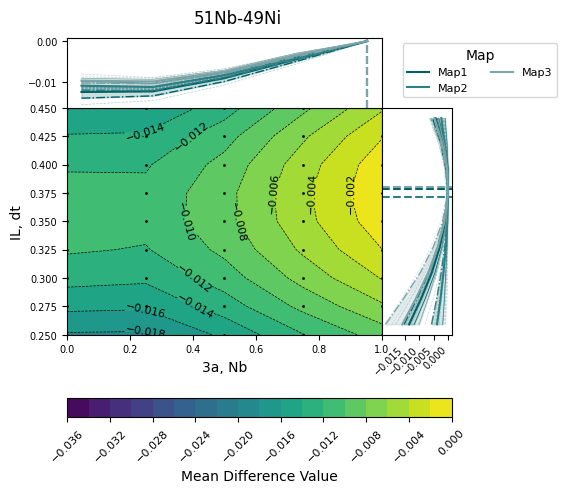

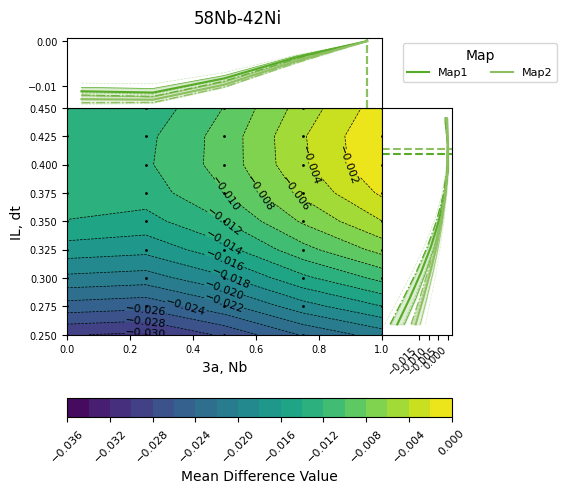

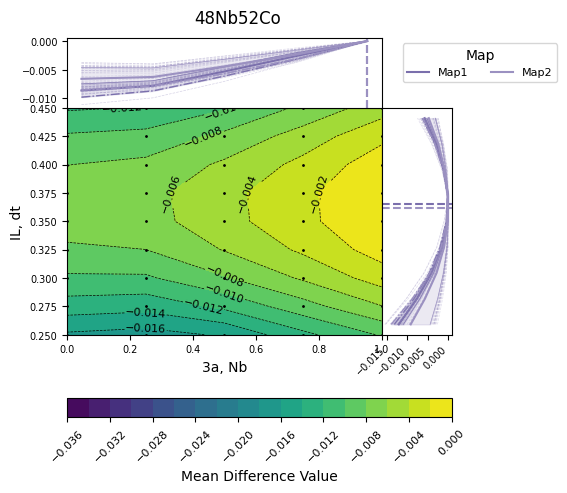

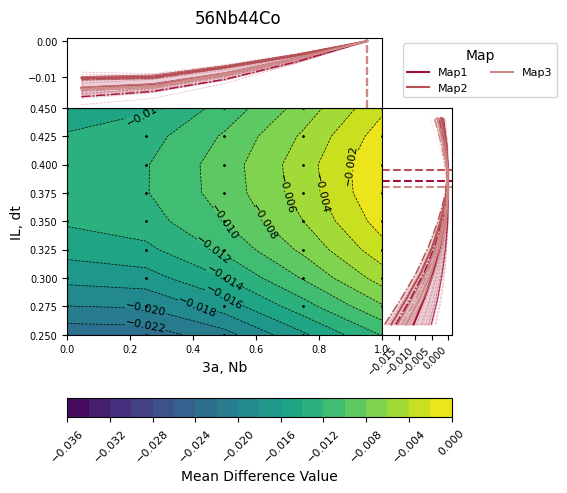

In [ ]:
colorList =[[colMan.RWTHPetrol.p(100),colMan.RWTHPetrol.p(75),colMan.RWTHPetrol.p(50),colMan.RWTHOrange.p(25)],
            [colMan.RWTHGruen.p(100),colMan.RWTHGruen.p(75),colMan.RWTHGruen.p(50),colMan.RWTHGruen.p(25)] ,
            [colMan.RWTHLila.p(100),colMan.RWTHLila.p(75),colMan.RWTHLila.p(50),colMan.RWTHLila.p(25)],
            [colMan.RWTHBordeaux.p(100),colMan.RWTHBordeaux.p(75),colMan.RWTHBordeaux.p(50),colMan.RWTHBordeaux.p(25)]]

plt.rcParams['xtick.labelsize'] = 7
plt.rcParams['ytick.labelsize'] = 7
from mpl_toolkits.axes_grid1 import make_axes_locatable
df_plot_eval_list = []
df_empty =              pd.DataFrame()
sampleNum = 0
for sample in dfAll['Sample'].unique():

    df_plot = dfAll[dfAll['Sample']==sample]
    df_plot["NbAndIL"]= df_plot["NbPlot"].astype(str) + '_'+ df_plot["ILPlot"].astype(str)
    df_plot["uniquePat"]= df_plot["Area"].astype(str) + '_'+ df_plot["Map"].astype(str)+ '_'+ df_plot["Tile"].astype(str)+ '_'+ df_plot["PatternNum"].astype(str)
    df_plot_grouped  = df_plot.groupby('NbAndIL').agg({"DiffValues": ["mean","std"],"ILPlot":"min","NbPlot":"min"}).reset_index() # technically the assignment of IL an dNbplot is a bit faulty. But the data should be fine to do it liket his
    # df_plot.groupby('NbAndIL').mean().reset_index()
    ## assing ipf colors
    # 
    # phase = read_phase_fromPhaseFile(df_plot["phase"].values[0]) 

   
   
   
    # Do a bit of reshaping



    grid_dims = ( len(df_plot_grouped["NbPlot"]["min"].unique()),
                len(df_plot_grouped["ILPlot"]["min"].unique()))

    IL_Grid = np.reshape(df_plot_grouped["ILPlot"]["min"].values, 
                        grid_dims)
    Nb_Grid = np.reshape(df_plot_grouped["NbPlot"]["min"].values, 
                        grid_dims )
    DiffValues_Grid = np.reshape(df_plot_grouped["DiffValues"]["mean"].values,
                                grid_dims)


    # import matplotlib.ticker as ticker
    # plt.style.use('default')
    # cm = 1/2.54

    fig,ax = plt.subplots(figsize=(9.5*cm*1.3,9.5*cm*1.3))

    fmt = ticker.StrMethodFormatter("{x:.3f}")
    contourLevels =np.arange(-0.036,0.0019,0.002) 

    cs = ax.contourf(Nb_Grid,IL_Grid,DiffValues_Grid,linewidths = 1,levels =contourLevels)# np.arange(-0.03,0.0019,0.002))

    cs_contour = ax.contour(cs, colors='k',linewidths=0.5)
    ax.clabel(cs_contour, fontsize=8,fmt=fmt)
    ax.set_xlabel("3a, Nb")

    ax.set_ylabel("IL, dt")
    ax.scatter(Nb_Grid.flatten(),IL_Grid.flatten(),s=1,color='black')
    cbar =fig.colorbar(cs,ax=ax,label='Mean Difference Value',orientation='horizontal',location='bottom',format = fmt) 
    cbar.ax.set_xticklabels(contourLevels,rotation=45,fontsize=8)
    cbar.formatter = fmt
    # cbar.xaxis.set_major_formatter(fmt)
    # plt.contour(IL_Grid,Nb_Grid,DiffValues_Grid)
    # ax.set_title(f'{sample} Mean NCC Difference Values \n over IL and 3a Nb grid')
    fig.tight_layout()
    plt.savefig(exportFolder.joinpath(f'{sample}_MeanDiffValues_IL_3aNb_grid.png'),bbox_inches='tight')
    divider = make_axes_locatable(ax)
    # below height and pad are in inches
    ax_Nb = divider.append_axes("top", 0.7, pad=0)#'', sharex=ax)
    ax_IL = divider.append_axes("right", 0.7, pad=0)#'', sharey=ax)

    # df_plot = dfAll[dfAll['Sample']==sample]
    df_plot["NbAndIL"]= df_plot["NbPlot"].astype(str) + '_'+ df_plot["ILPlot"].astype(str)
    df_plot["uniquePat"]= df_plot["Area"].astype(str) + '_'+ df_plot["Map"].astype(str)+ '_'+ df_plot["Tile"].astype(str)+ '_'+ df_plot["PatternNum"].astype(str)
    df_plot["area_micron"] =df_plot["area"]*df_plot["mapResolution"]**2

    # fig,ax = plt.subplots(1,2)
    ILValList = {}
    maxILList = {}
    NbValList = {}
    ILDeltaValList ={}
    maxNbList = {}  
    tile_num ={}
    pat_num = {}
    IL_xs = { }
    Nb_xs = {}
    area_micronList = {}
    phi1List = {}
    PhiList = {}
    phi2List  ={}
    phaseList = {}
    maxNCCList = {}
    uniqueMaps = df_plot["Map"].unique()
    for i in range(len(uniqueMaps)):
        ILValList[i]=[]
        ILDeltaValList[i] = []
        maxILList[i]=[]
        NbValList[i]=[]
        maxNbList[i]=[]
        tile_num[i] = []
        pat_num[i] = []
        IL_xs[i]=[]

        Nb_xs[i]=[]
        phi1List[i] =[]
        PhiList[i] = []
        phi2List[i] = []
        area_micronList[i] = []
        phaseList[i] = []
        maxNCCList[i] = []
    for uniquePat in df_plot["uniquePat"].unique():
            

        df_plot_uniquePat = df_plot[df_plot["uniquePat"]==uniquePat]
    
        maxIL = df_plot_uniquePat[df_plot_uniquePat["DiffValues"]==0]["ILPlot"].values[0]
        maxNb = df_plot_uniquePat[df_plot_uniquePat["DiffValues"]==0]["NbPlot"].values[0]
        ILVals = df_plot_uniquePat[df_plot_uniquePat["NbPlot"]==maxNb]["DiffValues"]
        IL_x = df_plot_uniquePat[df_plot_uniquePat["NbPlot"]==maxNb]["ILPlot"]
        NbVals = df_plot_uniquePat[df_plot_uniquePat["ILPlot"]==maxIL]["DiffValues"]
        Nb_x = df_plot_uniquePat[df_plot_uniquePat["ILPlot"]==maxIL]["NbPlot"]



        currentMap = df_plot_uniquePat["Map"].values[0] 
        colNum = np.where(uniqueMaps == currentMap)[0][0]
        color = colorList[colNum] 

        
        phi1List[colNum].append(df_plot_uniquePat["eangs_phi1"].unique()[0])
        PhiList[colNum].append(df_plot_uniquePat["eangs_Phi"].unique()[0])
        phi2List[colNum].append(df_plot_uniquePat["eangs_phi2"].unique()[0])
        area_micronList[colNum].append(df_plot_uniquePat["area_micron"].unique()[0])
        phaseList[colNum].append(df_plot_uniquePat["phase"].unique()[0]) 
        # print(ILVals[])
        maxILList[colNum].append(IL_x.values[np.where(max(ILVals.values)==ILVals.values)[0][0]])
        maxNbList[colNum].append(Nb_x.values[np.where(max(NbVals.values)==NbVals.values)[0][0]])

        maxNCCList[colNum].append(np.max(df_plot_uniquePat["allMetricsCombined"]))

        ILVals_reset = ILVals.reset_index()
        ILVals_reset.loc[2,"DiffValues"]-ILVals_reset.loc[4,"DiffValues"]


        IL_xs[colNum]=IL_x.values
        Nb_xs[colNum]=Nb_x.values
        tile_num[colNum].append(df_plot_uniquePat.Tile.unique()[0])
        pat_num[colNum].append(df_plot_uniquePat.PatternNum.unique()[0])
        NbValList[colNum].append(NbVals.values)
        ILValList[colNum].append(ILVals.values)  
        # ILDeltaValList[colNum].append(ILVals_reset)
        # ILVals_reset = ILVals.reset_index()
        # ILDeltaValList[colNum].append(ILVals_reset.loc[2,"DiffValues"]-ILVals_reset.loc[4,"DiffValues"])
      
        # ILValList[colNum].append(ILVals)
        # ILValList[colNum}"]
    # df_plot_loc = pd.DataFrame()


    # df_plot_AreaFilterd = 
    for colNum in range(len(uniqueMaps)):
        print(colNum)
        plotColor = colorList[sampleNum][colNum]
        outlierFilter = np.where(abs(maxILList[colNum]-np.mean(maxILList[colNum])) < np.max([(np.std(maxILList[colNum])*2),0.05]))
        outlierFilterNb = np.where(abs(maxNbList[colNum]-np.mean(maxNbList[colNum])) < np.max([np.std(maxNbList[colNum])*2,0.25]))
        plotValsIL = np.array(ILValList[colNum])[outlierFilter]
        plotValsNb = np.array(NbValList[colNum])[outlierFilterNb]
        # patternNums = df_plot[df_plot['Map']==uniqueMaps[colNum]]["PatternNum"]
        # patternNums = df_plot[df_plot['Map']==uniqueMaps[colNum]]["PatternNum"].unique()
        patternNums = pat_num[colNum]
        patternNums =  np.array(pat_num[colNum])[outlierFilter]
        maxNCC = np.array( maxNCCList[colNum])[outlierFilter]
            # maxNCCList[colNum].append(np.max(df_plot_uniquePat["allMetricsCombined"]))
        Phi = np.array(PhiList[colNum])[outlierFilter]
        phi2 = np.array(phi2List[colNum])[outlierFilter]
        phi1 = np.array(phi1List[colNum])[outlierFilter]
        area_micron = np.array(area_micronList[colNum])[outlierFilter]
        phase = phaseList[colNum]
        ILVals_plot = IL_xs[colNum]
        NbVals_plot = Nb_xs[colNum]
        f_xValues=np.linspace(min(ILVals_plot),max(ILVals_plot),100)

        for ValNum in range(0,plotValsIL.shape[0]):
            df_plot_loc = pd.DataFrame(columns=['maxILNCC'])
            df_plot_loc.at[0,'maxILNCC']=0
            [params,cov]=curve_fit(polynomial4,ILVals_plot,plotValsIL[ValNum])
            plotValues = polynomial4(f_xValues,params[0],params[1],params[2],params[3],params[4])
            df_plot_loc['maxILNCC'] = max(plotValues)
            df_plot_loc["Delta2_Delta4"] = plotValsIL[ValNum][4]-plotValsIL[ValNum][2]
            df_plot_loc['maxIL'] = f_xValues[np.argmax(plotValues)]
            df_plot_loc['map'] = uniqueMaps[colNum]
            df_plot_loc['pNum'] = patternNums[ValNum]
            df_plot_loc['Sample'] = df_plot["Sample"].unique()[0]
            df_plot_loc["Area_micron"] = area_micron[ValNum]
            df_plot_loc["phi1"] = phi1[ValNum]
            df_plot_loc["phi2"] = phi2[ValNum]
            df_plot_loc["Phi"]= Phi[ValNum]
            df_plot_loc["phase"] = phase[ValNum]
            df_plot_loc["maxNCC"] = maxNCC[ValNum]

            # df_plot_loc["ILDeltaVal"] = ILDeltaValList[ValNum]
            for col in eds_columns:
                df_plot_loc[col] = df_plot[df_plot["PatternNum"]==patternNums[ValNum]][col].unique()[0]
            df_plot_eval_list.append(df_plot_loc)

        meanValIL = np.mean(plotValsIL,0) 
        stdValIL = np.std(plotValsIL,0)

        ax_IL.plot(np.mean(plotValsIL,0),ILVals_plot,color=plotColor)
        ax_IL.plot(np.transpose(plotValsIL),ILVals_plot,color=plotColor,alpha=0.3,linestyle='--',linewidth=0.5)
        ax_IL.plot(meanValIL+stdValIL,ILVals_plot,color = plotColor ,linewidth=0.5)
        ax_IL.plot(meanValIL-stdValIL,ILVals_plot,plotColor,linewidth=1,linestyle = '-.' )
        ax_IL.fill_betweenx(ILVals_plot, meanValIL-stdValIL, meanValIL+stdValIL, color=plotColor, alpha=0.2)


        meanValNb = np.mean(plotValsNb,0)
        stdValNb = np.std(plotValsNb,0)

        
        ax_Nb.plot(NbVals_plot,np.mean(plotValsNb,0),color=plotColor,label = uniqueMaps[colNum] )
        ax_Nb.plot(NbVals_plot,np.transpose(plotValsNb),color=plotColor,alpha=0.3,linestyle='--',linewidth=0.5)
        ax_Nb.plot(NbVals_plot,meanValNb+stdValNb,color = plotColor ,linewidth=0.5)
        ax_Nb.plot(NbVals_plot,meanValNb-stdValNb,plotColor,linewidth=1,linestyle = '-.' )
        ax_Nb.fill_between(NbVals_plot, meanValNb-stdValNb, meanValNb+stdValNb, color=plotColor, alpha=0.2)
    # from scipy.optimize import curve_fit

   

        [params,cov]=curve_fit(polynomial4,ILVals_plot,meanValIL)
        f_xValues=np.linspace(min(ILVals_plot),max(ILVals_plot),100)
        plotValues = polynomial4(f_xValues,params[0],params[1],params[2],params[3],params[4])
        # f(f_xValues,params[0],params[1],params[2],params[3],params[4])
        maxIL = f_xValues[plotValues.argmax()]
        # plt.plot(plotValues,f_xValues)
        # plt.plot(meanVal,ILVals_plot)
        ax_IL.axhline(y=maxIL,color=plotColor,linestyle='--')


        [params,cov]=curve_fit(polynomial4,NbVals_plot,meanValNb)
        f_xValues=np.linspace(min(NbVals_plot),max(NbVals_plot),100)
        plotValues = polynomial4(f_xValues,params[0],params[1],params[2],params[3],params[4])
        # f(f_xValues,params[0],params[1],params[2],params[3],params[4])
        maxIL = f_xValues[plotValues.argmax()]
        # plt.plot(plotValues,f_xValues)
        # plt.plot(meanVal,ILVals_plot)
        ax_Nb.axvline(x=maxIL,color=plotColor,linestyle='--')
    # a
    sampleNum+=1
    ax_IL.set_yticks([])
    ax_Nb.set_xticks([])
    # ax_IL.set_xticklabels([], rotation=45, ha='right')
    ax_IL.set_xticks([-0.015,-0.01,-0.005,0])
    ax_IL.set_xticklabels(ax_IL.get_xticklabels(), rotation=45, ha='right')
    # ax_IL:
    ax_Nb.legend(title='Map',bbox_to_anchor=(1.05, 1), loc='upper left',fontsize = 8,ncols = 2)
    fig.suptitle(df_plot_uniquePat["Sample"].unique()[0],y=1.02)
    # dfPlot_eval_areaList
    plt.savefig(exportFolder.joinpath(f'{sample}_MeanDiffValues_IL_3aNb_grid_addAxes.png'),bbox_inches='tight',dpi=300)
    plt.savefig(exportFolder.joinpath(f'{sample}_MeanDiffValues_IL_3aNb_grid_addAxes.svg'),bbox_inches='tight')
    plt.savefig(exportFolder.joinpath(f'{sample}_MeanDiffValues_IL_3aNb_grid_addAxes.pdf'),bbox_inches='tight')
    # a

### Test orientation based plotting

In [ ]:
# df_plot_all_eval 
from importlib import reload
import orix


reload(c_map)
df_plot_all_eval = pd.concat(df_plot_eval_list)
df_plotList = []
for phaseString in df_plot_all_eval['phase'].unique():
    df_plot_all_eval_phaseUnique = df_plot_all_eval[df_plot_all_eval['phase']==phaseString].copy()
    eangs = [df_plot_all_eval_phaseUnique["phi1"].values,df_plot_all_eval_phaseUnique["Phi"].values,df_plot_all_eval_phaseUnique["phi2"].values]
    eangs = np.array(eangs)
    phase = read_phase_fromPhaseFile(phaseString)
    ori=quaternion.Orientation.from_euler(eangs.transpose(),phase.point_group)
    v = Vector3d([[1, 0, 0], [0, 1, 0], [0, 0, 1]])


    ipfkey_z = plot.IPFColorKeyTSL(phase.point_group)
    ipfkey_x = plot.IPFColorKeyTSL(phase.point_group,v[0])
    ipfkey_y = plot.IPFColorKeyTSL(phase.point_group,v[1])
    # ori.symmetry = ipfkey.symmetry
    rgb_z = ipfkey_z.orientation2color(ori)
    rgb_x = ipfkey_x.orientation2color(ori)
    rgb_y = ipfkey_y.orientation2color(ori)
    r_z = rgb_z[:,0] 
    g_z = rgb_z[:,1]
    b_z = rgb_z[:,2]

    r_x = rgb_x[:,0] 
    g_x = rgb_x[:,1]
    b_x = rgb_x[:,2]

    r_y = rgb_y[:,0] 
    g_y = rgb_y[:,1]
    b_y = rgb_y[:,2]
    rgb_x = ipfkey_x.orientation2color(ori)
    rgb_y = ipfkey_y.orientation2color(ori)
    df_plot_all_eval_phaseUnique["r_z"]=r_z
    df_plot_all_eval_phaseUnique["g_z"]=g_z
    df_plot_all_eval_phaseUnique["b_z"]=b_z

    df_plot_all_eval_phaseUnique["r_x"]=r_x
    df_plot_all_eval_phaseUnique["g_x"]=g_x
    df_plot_all_eval_phaseUnique["b_x"]=b_x
    
    df_plot_all_eval_phaseUnique["r_y"]=r_y
    df_plot_all_eval_phaseUnique["g_y"]=g_y
    df_plot_all_eval_phaseUnique["b_y"]=b_y

    df_plotList.append(df_plot_all_eval_phaseUnique)
df_plot_all_eval= pd.concat(df_plotList)
df_plot_all_eval.reset_index(inplace=True)
df_plot_all_eval.to_csv(exportFolder.joinpath("result_area_weighted.csv"))

NbNi_c26.81_a4.92_6c2-0.250_3aNb-0.000_.cif
NbNi_c27.025_a4.96_6c2-0.250_3aNb-0.000_.cif


c:\Users\berners\random_projects_lukas\.venv_312\Lib\site-packages\diffpy\structure\parsers\p_cif.py:506: UserWarning: Skipping f{fset}
  warnings.warn("Skipping f{fset}")
c:\Users\berners\random_projects_lukas\.venv_312\Lib\site-packages\diffpy\structure\parsers\p_cif.py:506: UserWarning: Skipping f{fset}
  warnings.warn("Skipping f{fset}")


NbCo_a4.92_c26.25_LowNb_6c2-0.250_3aNb-0.000_.cif
NbCo_a4.98_c26.50_HighNb_6c2-0.250_3aNb-0.000_.cif


c:\Users\berners\random_projects_lukas\.venv_312\Lib\site-packages\diffpy\structure\parsers\p_cif.py:506: UserWarning: Skipping f{fset}
  warnings.warn("Skipping f{fset}")
c:\Users\berners\random_projects_lukas\.venv_312\Lib\site-packages\diffpy\structure\parsers\p_cif.py:506: UserWarning: Skipping f{fset}
  warnings.warn("Skipping f{fset}")


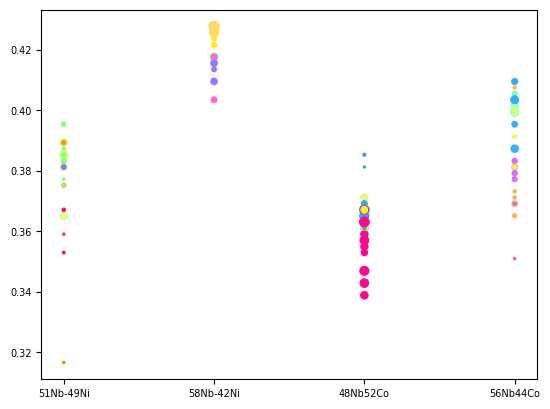

In [ ]:
df_plot_all_eval
colorList = np.array([df_plot_all_eval["r_z"],df_plot_all_eval["g_z"],df_plot_all_eval["b_z"]])
plt.scatter(df_plot_all_eval['Sample'],df_plot_all_eval.maxIL,s=df_plot_all_eval.Area_micron,c=colorList.transpose())


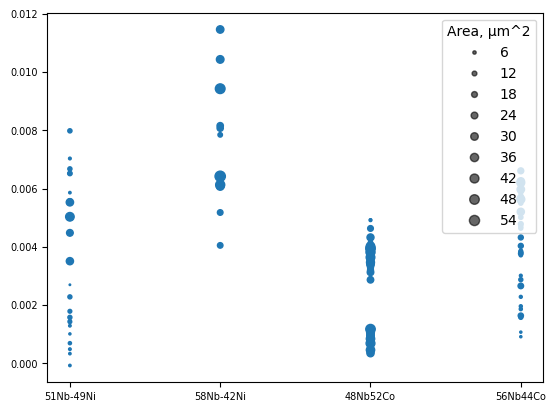

In [ ]:
scatter = plt.scatter(df_plot_all_eval["Sample"],df_plot_all_eval["Delta2_Delta4"],s=df_plot_all_eval.Area_micron)

handles, labels = scatter.legend_elements(prop="sizes", alpha=0.6)
legend2 = plt.legend(handles, labels, loc="upper right", title="Area, µm^2")

In [ ]:
delta2_4group = df_plot_all_eval.groupby("Sample").agg({"Delta2_Delta4": ["mean","std"]}).reset_index()
# plt.scatter(df_plot_all_eval["Sample"],df_plot_all_eval["Delta2_Delta4"],s=df_plot_all_eval.Area_micron)
# delta2_4group.to_latex()
with open(exportFolder.joinpath(f'Delta2_Delta4.txt'),"w") as f:
    delta2_4group.to_latex(f)

In [ ]:
exportFolder

WindowsPath('J:/Users/Berners_Lukas/clara/NbNi_septemberbatch/muPhaseEval_results')

In [ ]:
df_plot_all_eval["SampleNumber"] = -1
sampleNum = 0
for uniqueSample in df_plot_all_eval["Sample"].unique():
    indices = df_plot_all_eval[df_plot_all_eval["Sample"] ==uniqueSample].index
    for i in indices:
        df_plot_all_eval.loc[i,"SampleNumber"]= sampleNum
    sampleNum+=1
    print(sampleNum)
    print(uniqueSample)
    print(sum(df_plot_all_eval[df_plot_all_eval["Sample"] ==uniqueSample]["Area_micron"]))
    print("\n")
df_plot_all_eval
    

1
51Nb-49Ni
231.00000000000003


2
58Nb-42Ni
345.8800103764001


3
48Nb52Co
943.8800000000002


4
56Nb44Co
367.9200110376001




,index,maxILNCC,Delta2_Delta4,maxIL,map,pNum,Sample,Area_micron,phi1,phi2,...,r_z,g_z,b_z,r_x,g_x,b_x,r_y,g_y,b_y,SampleNumber
0,0,0.000117,0.005033,0.385354,Map1,1,51Nb-49Ni,37.76,4.147310,6.026043,...,0.868086,1.000000,0.487431,1.0,0.841099,0.138240,0.649776,1.000000,0.107710,0
1,0,0.000084,0.005529,0.389394,Map1,5,51Nb-49Ni,27.96,4.150920,6.024898,...,0.864372,1.000000,0.490468,1.0,0.835314,0.136969,0.645557,1.000000,0.102497,0
2,0,0.000077,0.004481,0.381313,Map1,10,51Nb-49Ni,23.04,4.142973,6.029879,...,0.865811,1.000000,0.480232,1.0,0.844690,0.140119,0.654660,1.000000,0.105526,0
3,0,0.000046,0.004971,0.389394,Map1,14,51Nb-49Ni,8.08,4.145029,6.026859,...,0.865535,1.000000,0.486316,1.0,0.841119,0.142619,0.653242,1.000000,0.107581,0
4,0,0.000045,0.003509,0.365152,Map1,21,51Nb-49Ni,27.00,4.143394,6.027641,...,0.872480,1.000000,0.483354,1.0,0.847908,0.138655,0.654076,1.000000,0.113071,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101,0,0.000008,0.003834,0.377273,Map3,4,56Nb44Co,8.92,4.202332,2.922357,...,0.861900,0.413399,1.000000,1.0,0.026592,0.818716,0.558706,0.030099,1.000000,3
102,0,0.000019,0.003876,0.369192,Map3,5,56Nb44Co,4.48,4.203950,2.920308,...,0.857958,0.418120,1.000000,1.0,0.022277,0.814656,0.558378,0.031025,1.000000,3
103,0,-0.000065,0.004034,0.379293,Map3,1,56Nb44Co,12.92,4.209074,5.013212,...,0.857920,0.421071,1.000000,1.0,0.028241,0.808762,0.553279,0.035154,1.000000,3
104,0,-0.000075,0.004697,0.399495,Map3,2,56Nb44Co,8.56,4.201495,1.873340,...,0.858332,1.000000,0.417654,1.0,0.818558,0.018540,0.562446,1.000000,0.028173,3


In [ ]:
df_plot_all_eval["Area_micron"]

0      37.76
1      27.96
2      23.04
3       8.08
4      27.00
       ...  
101     8.92
102     4.48
103    12.92
104     8.56
105    10.92
Name: Area_micron, Length: 106, dtype: float64

In [ ]:
def reindex_df(df, weight_col):
    """expand the dataframe to prepare for resampling
    result is 1 row per count per sample"""
    df = df.reindex(df.index.repeat(df[weight_col]))
    df.reset_index(drop=True, inplace=True)
    return(df)

# df_reinedex = reindex_df(df, weight_col = 'area_micron')
# 
# sns.boxplot(x='Name', y='Score', data=df)

<Axes.ArtistList of 0 artists>


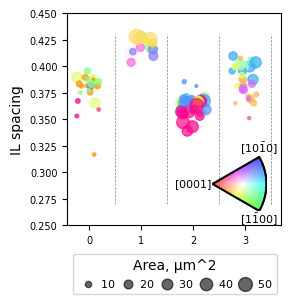

In [ ]:
fig,ax = plt.subplots(figsize=(7*cm,7*cm))
alpha = 0.7
colorList = np.array([df_plot_all_eval["r_z"],df_plot_all_eval["g_z"],df_plot_all_eval["b_z"]])
scatter = ax.scatter(df_plot_all_eval['SampleNumber'].values+np.random.rand(len(df_plot_all_eval["Sample"]))*0.5-0.25,
        df_plot_all_eval.maxIL,
        s=df_plot_all_eval.Area_micron*2,
        c=colorList.transpose(),
        alpha = alpha)
ax.vlines([0.5,1.5,2.5,3.5],0.27,0.43,'gray',linestyles='--',linewidth=0.5)
# plt.scatter(df_plot_)
# ax.set_xticks([0,1,2,3])
# ax.set_xticklabels(df_plot_all_eval["Sample"].unique(),rotation=20)
ax.set_ylabel('IL spacing')
# ax.set_xlabel("Sample")
ax.set_ylim(0.25,0.45)
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_noIPFKey.png'),bbox_inches='tight',dpi=300)
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_noIPFKey.svg'),bbox_inches='tight')
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_noIPFKey.pdf'),bbox_inches='tight')
ax_ipf = fig.add_axes([0.65, 0.16, 0.2, 0.2], projection="ipf", symmetry=ori.symmetry, zorder=2)
ax_ipf.plot_ipf_color_key(show_title=False)
ax_ipf.patch.set_facecolor("None")
# ax_ipf.patch.set_alpha = 0.5
print(ax_ipf.artists)

# ax_ipf.set_labels(xlabel="")
# ax_ipf.set_labels(fontsize =10)
# ax.plot(df_plot_all_eval.maxIL)
from matplotlib.text import Text
from matplotlib.image import AxesImage 
matches = ax_ipf.findobj(lambda artist: isinstance(artist, Text) and "[" in artist.get_text() )
matches
for match in matches:
    match.set_fontsize(8)

matches = ax_ipf.findobj(lambda artist: isinstance(artist, AxesImage) )
matches
for match in matches:
    match.set_alpha(alpha)

handles, labels = scatter.legend_elements(prop="sizes",num=5,func= lambda x: x/2, alpha=0.6)
legend2 = ax.legend(handles, labels, loc="lower left", title="Area, µm^2",
                    ncols=5,
                    bbox_to_anchor=(0,-0.35),#,0.5,0.2),
                    fontsize=8,
                    title_fontsize=10,
                    handletextpad=0.05,
                    columnspacing=0.1)

plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting.png'),bbox_inches='tight',dpi=300)
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting.svg'),bbox_inches='tight')
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting.pdf'),bbox_inches='tight')

In [ ]:
df_IL_mean= df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.average(x.maxNCC, weights=x.Area_micron))
df_IL_mean = pd.DataFrame(df_IL_mean)
df_IL_STD = pd.DataFrame(df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.sqrt(np.cov(x.maxNCC, aweights=x.Area_micron))))
df_IL_mean = df_IL_mean.join(df_IL_STD,lsuffix='mean',rsuffix='std')
with open(exportFolder.joinpath(f'IL_results.txt'),"w") as f:
    df_IL_mean.to_latex(f)
df_IL_mean.to_csv(exportFolder.joinpath(f'IL_results.csv'))

C:\Users\berners\AppData\Local\Temp\ipykernel_18656\3956114081.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_IL_mean= df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.average(x.maxNCC, weights=x.Area_micron))
C:\Users\berners\AppData\Local\Temp\ipykernel_18656\3956114081.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_IL_STD = pd.DataFrame(df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np

In [ ]:
df_plot_all_eval["Sample"].unique()

array(['51Nb-49Ni', '58Nb-42Ni', '48Nb52Co', '56Nb44Co'], dtype=object)

In [ ]:
df_plot_all_eval[df_plot_all_eval["Sample"]=="58Nb-42Ni"]

,index,maxILNCC,Delta2_Delta4,maxIL,map,pNum,Sample,Area_micron,phi1,phi2,...,r_z,g_z,b_z,r_x,g_x,b_x,r_y,g_y,b_y,SampleNumber
24,0,0.000057,0.010432,0.417677,Map1,1,58Nb-42Ni,30.000001,2.427099,6.042839,...,0.525453,1.000000,0.495352,0.959077,1.000000,0.064861,1.0000,0.738863,0.638479,1
25,0,0.000106,0.009427,0.411616,Map1,2,58Nb-42Ni,48.720001,1.934557,5.728266,...,0.978580,0.940952,1.000000,1.000000,0.121647,0.656541,0.4825,0.326323,1.000000,1
26,0,0.000120,0.008157,0.415657,Map1,3,58Nb-42Ni,20.960001,2.423423,2.902465,...,0.537422,0.492475,1.000000,0.955021,0.044135,1.000000,1.0000,0.628591,0.748721,1
27,0,-0.000060,0.011459,0.427778,Map1,6,58Nb-42Ni,28.640001,2.429125,1.853746,...,0.528341,1.000000,0.495889,0.954853,1.000000,0.062857,1.0000,0.738367,0.633515,1
28,0,-0.000032,0.008071,0.409596,Map1,7,58Nb-42Ni,20.120001,2.419850,2.904311,...,0.537103,0.488764,1.000000,0.959453,0.042730,1.000000,1.0000,0.630675,0.752372,1
29,0,0.000160,0.007844,0.413636,Map1,9,58Nb-42Ni,10.560000,2.425563,2.902144,...,0.540331,0.493017,1.000000,0.950659,0.042333,1.000000,1.0000,0.623463,0.748188,1
30,0,-0.000008,0.006421,0.427778,Map2,1,58Nb-42Ni,55.240002,3.591912,2.348146,...,1.000000,0.857604,0.408066,0.432111,1.000000,0.101023,1.0000,0.927936,0.293958,1
31,0,0.000119,0.005179,0.417677,Map2,2,58Nb-42Ni,16.360000,0.455185,3.937041,...,1.000000,0.404980,0.857823,0.434817,0.104376,1.000000,1.0000,0.288026,0.931601,1
32,0,0.000018,0.006327,0.421717,Map2,3,58Nb-42Ni,14.560000,0.584720,3.269288,...,1.000000,0.902555,0.206971,0.660797,1.000000,0.458890,1.0000,0.908925,0.701231,1
33,0,0.000060,0.006079,0.425758,Map2,4,58Nb-42Ni,32.640001,3.588500,2.349986,...,1.000000,0.859319,0.411773,0.428926,1.000000,0.098263,1.0000,0.923252,0.295285,1


In [ ]:
# for 
# plt.scatter(df_plot_all_eval["Sample"].values,df_plot_all_eval["nbl_at____mean"].values,)

In [ ]:
df_plot_all_eval.to_csv(exportFolder.joinpath(f'IL_results_ncc_nonAv.csv'))

In [ ]:
df_IL_mean= df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.average(x.maxNCC, weights=x.Area_micron))
df_IL_mean = pd.DataFrame(df_IL_mean)
df_IL_STD = pd.DataFrame(df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.sqrt(np.cov(x.maxNCC, aweights=x.Area_micron))))
df_IL_mean = df_IL_mean.join(df_IL_STD,lsuffix='mean',rsuffix='std')
with open(exportFolder.joinpath(f'IL_results_ncc.txt'),"w") as f:
    df_IL_mean.to_latex(f)
df_IL_mean.to_csv(exportFolder.joinpath(f'IL_results_ncc.csv'))

C:\Users\berners\AppData\Local\Temp\ipykernel_18656\563228559.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_IL_mean= df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.average(x.maxNCC, weights=x.Area_micron))
C:\Users\berners\AppData\Local\Temp\ipykernel_18656\563228559.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_IL_STD = pd.DataFrame(df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.s

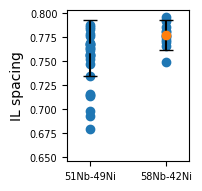

In [ ]:
# ax_ipf.findobj()
fig,ax=plt.subplots(figsize=[4*cm,5*cm])
# dfPlot = df_IL_mean.loc["51Nb-"]
sample = "51Nb-49Ni"
plt.errorbar(sample, df_IL_mean.loc[sample,"0mean"], yerr=df_IL_mean.loc[sample,"0std"], fmt='o', ecolor='black', capsize=5)
plt.scatter(df_plot_all_eval["Sample"],df_plot_all_eval["maxNCC"])
sample = "58Nb-42Ni"
plt.errorbar(sample, df_IL_mean.loc[sample,"0mean"], yerr=df_IL_mean.loc[sample,"0std"], fmt='o', ecolor='black', capsize=5)
# plt.ylim([0.25,0.45])
plt.xlim([-0.3,1.3])
plt.ylabel('IL spacing')
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_HighBethe_deviations.png'),bbox_inches='tight',dpi=300)
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_HighBethe_deviations.svg'),bbox_inches='tight')
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_HIgh_Behte__deviations.pdf'),bbox_inches='tight')

In [ ]:
fig,ax = plt.subplots(figsize=(7*cm,7*cm))
alpha = 0.7
markers = ['D','s','<','v']

for i,sample in enumerate(df_plot_all_eval["Sample"].unique()):
    dfPlotLoc = df_plot_all_eval[df_plot_all_eval["Sample"]==sample]
    if not "51Nb-49Ni" in sample:
        continue

    colorList = np.array([dfPlotLoc["r_z"],dfPlotLoc["g_z"],dfPlotLoc["b_z"]])
    ax.scatter(dfPlotLoc["nbl_at____mean"].values,
            dfPlotLoc.maxIL,
            s=dfPlotLoc.Area_micron*2,
            c=colorList.transpose(),
            alpha = alpha,
            marker=markers[i],label=sample)
    # ax.errorbar(dfPlotLoc["nik_at____mean"].values, dfPlotLoc.maxIL, xerr=dfPlotLoc["nik_at____std"].values, linewidth=0 , elinewidth=0.5,marker='none',color='black',capsize=1)
    # , fmt='none', ecolor=colorList.transpose(), alpha=alpha)
    for x,y, text,text2 in zip(dfPlotLoc["nik_at____mean"].values,dfPlotLoc.maxIL,dfPlotLoc["map"].values,dfPlotLoc["pNum"].values):
        ax.text(x,y,f"{text}_{text2}",fontsize=6)
        ax.text(dfPlotLoc["nik_at____mean"].values,dfPlotLoc.maxIL,dfPlotLoc["map"].values)
# ax.vlines([0.5,1.5,2.5,3.5],0.27,0.43,'gray',linestyles='--',linewidth=0.5)
# plt.scatter(df_plot_)
# ax.set_xticks([0,1,2,3])
# ax.set_xticklabels(df_plot_all_eval["Sample"].unique(),rotation=20)
ax.set_ylabel('IL spacing')
ax.set_xlabel("Nb, at%")
# ax.set_xlabel("Sample")
ax.set_ylim(0.25,0.45)
# plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_noIPFKey.png'),bbox_inches='tight',dpi=300)
# plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_noIPFKey.svg'),bbox_inches='tight')
# plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_noIPFKey.pdf'),bbox_inches='tight')
ax_ipf = fig.add_axes([0.65, 0.16, 0.2, 0.2], projection="ipf", symmetry=ori.symmetry, zorder=2)
ax_ipf.plot_ipf_color_key(show_title=False)
ax_ipf.patch.set_facecolor("None")
# ax_ipf.patch.set_alpha = 0.5
print(ax_ipf.artists)
ax.legend(bbox_to_anchor=(0.5, -0.3), loc='upper left',fontsize = 8,ncols=2)
ax.set_xlim([50,60])
# ax_ipf.set_labels(xlabel="")
# ax_ipf.set_labels(fontsize =10)
# ax.plot(df_plot_all_eval.maxIL)
# ax.set_ylim(0.325,0.45)
from matplotlib.text import Text
from matplotlib.image import AxesImage 
matches = ax_ipf.findobj(lambda artist: isinstance(artist, Text) and "[" in artist.get_text() )
matches
for match in matches:
    match.set_fontsize(8)

matches = ax_ipf.findobj(lambda artist: isinstance(artist, AxesImage) )
matches
for match in matches:
    match.set_alpha(alpha)
# plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting.png'),bbox_inches='tight',dpi=300)
# plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting.svg'),bbox_inches='tight')
# plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting.pdf'),bbox_inches='tight')
# # plt.xlim(50,70)

<Axes.ArtistList of 0 artists>
Error in callback <function _draw_all_if_interactive at 0x000001A7CEDF4D60> (for post_execute), with arguments args (),kwargs {}:


TypeError: only length-1 arrays can be converted to Python scalars

TypeError: only length-1 arrays can be converted to Python scalars

<Figure size 275.591x275.591 with 2 Axes>

In [ ]:
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting.png'),bbox_inches='tight',dpi=300)


<Figure size 640x480 with 0 Axes>

In [ ]:
df_plot_all_eval

,index,maxILNCC,maxIL,map,pNum,Sample,Area_micron,phi1,phi2,Phi,...,r_z,g_z,b_z,r_x,g_x,b_x,r_y,g_y,b_y,SampleNumber
0,0,0.000117,0.385354,Map1,1,51Nb-49Ni,37.76,4.147310,6.026043,1.019192,...,0.868086,1.000000,0.487431,1.0,0.841099,0.138240,0.649776,1.000000,0.107710,0
1,0,0.000084,0.389394,Map1,5,51Nb-49Ni,27.96,4.150920,6.024898,1.022167,...,0.864372,1.000000,0.490468,1.0,0.835314,0.136969,0.645557,1.000000,0.102497,0
2,0,0.000077,0.381313,Map1,10,51Nb-49Ni,23.04,4.142973,6.029879,1.019298,...,0.865811,1.000000,0.480232,1.0,0.844690,0.140119,0.654660,1.000000,0.105526,0
3,0,0.000046,0.389394,Map1,14,51Nb-49Ni,8.08,4.145029,6.026859,1.020628,...,0.865535,1.000000,0.486316,1.0,0.841119,0.142619,0.653242,1.000000,0.107581,0
4,0,0.000045,0.365152,Map1,21,51Nb-49Ni,27.00,4.143394,6.027641,1.015586,...,0.872480,1.000000,0.483354,1.0,0.847908,0.138655,0.654076,1.000000,0.113071,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101,0,0.000008,0.377273,Map3,4,56Nb44Co,8.92,4.202332,2.922357,1.009319,...,0.861900,0.413399,1.000000,1.0,0.026592,0.818716,0.558706,0.030099,1.000000,3
102,0,0.000019,0.369192,Map3,5,56Nb44Co,4.48,4.203950,2.920308,1.012693,...,0.857958,0.418120,1.000000,1.0,0.022277,0.814656,0.558378,0.031025,1.000000,3
103,0,-0.000065,0.379293,Map3,1,56Nb44Co,12.92,4.209074,5.013212,1.013249,...,0.857920,0.421071,1.000000,1.0,0.028241,0.808762,0.553279,0.035154,1.000000,3
104,0,-0.000075,0.399495,Map3,2,56Nb44Co,8.56,4.201495,1.873340,1.012559,...,0.858332,1.000000,0.417654,1.0,0.818558,0.018540,0.562446,1.000000,0.028173,3


In [ ]:
df_IL_mean= df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.average(x.maxIL, weights=x.Area_micron))
df_IL_mean = pd.DataFrame(df_IL_mean)
df_IL_STD = pd.DataFrame(df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.sqrt(np.cov(x.maxIL, aweights=x.Area_micron))))
df_IL_mean = df_IL_mean.join(df_IL_STD,lsuffix='mean',rsuffix='std')
with open(exportFolder.joinpath(f'IL_results.txt'),"w") as f:
    df_IL_mean.to_latex(f)
df_IL_mean.to_csv(exportFolder.joinpath(f'IL_results.csv'))


C:\Users\berners\AppData\Local\Temp\ipykernel_18656\3356634925.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_IL_mean= df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.average(x.maxIL, weights=x.Area_micron))
C:\Users\berners\AppData\Local\Temp\ipykernel_18656\3356634925.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_IL_STD = pd.DataFrame(df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.

<Figure size 640x480 with 0 Axes>

In [ ]:
df_IL_mean.loc["51Nb-49Ni","0mean"]

np.float64(0.3803896103896104)

In [ ]:
df_IL_mean.loc[sample].index

Index(['0mean', '0std'], dtype='object')

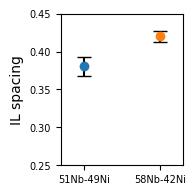

In [ ]:
# d
# dfPlot = 
fig,ax=plt.subplots(figsize=[4*cm,5*cm])
dfPlot = df_IL_mean.loc["51Nb-49Ni"]
sample = "51Nb-49Ni"
plt.errorbar(sample, df_IL_mean.loc[sample,"0mean"], yerr=df_IL_mean.loc[sample,"0std"], fmt='o', ecolor='black', capsize=5)
sample = "58Nb-42Ni"
plt.errorbar(sample, df_IL_mean.loc[sample,"0mean"], yerr=df_IL_mean.loc[sample,"0std"], fmt='o', ecolor='black', capsize=5)
plt.ylim([0.25,0.45])
plt.xlim([-0.3,1.3])
plt.ylabel('IL spacing')
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_deviations.png'),bbox_inches='tight',dpi=300)
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_deviations.svg'),bbox_inches='tight')
plt.savefig(exportFolder.joinpath(f'IL_3aNb_IPFAndAreaWeighting_deviations.pdf'),bbox_inches='tight')

In [ ]:
dfPlot

0mean    0.380390
0std     0.012182
Name: 51Nb-49Ni, dtype: float64

In [ ]:
plotValuesRay

{'d3a_6c2': [np.float64(0.271672725333333), np.float64(0.363118671933333)],
 'd18h_6c2': [np.float64(1.69975644426667), np.float64(1.66963125766667)],
 'd18h_6c3': [np.float64(1.03694776393333), np.float64(1.01575920073333)],
 'd6c3_6c1': [np.float64(1.2785077854), np.float64(1.2755942914)]}

In [ ]:
df_IL_mean.join(df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.sqrt(np.cov(x.maxIL, aweights=x.Area_micron))))

C:\Users\berners\AppData\Local\Temp\ipykernel_18656\3837736656.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_IL_mean.join(df_plot_all_eval.groupby(["Sample"]).apply(lambda x: np.sqrt(np.cov(x.maxIL, aweights=x.Area_micron))))


ValueError: Other Series must have a name

In [ ]:
exportFolder


WindowsPath('J:/Users/Berners_Lukas/clara/NbNi_septemberbatch/muPhaseEval_results')

<Axes.ArtistList of 0 artists>


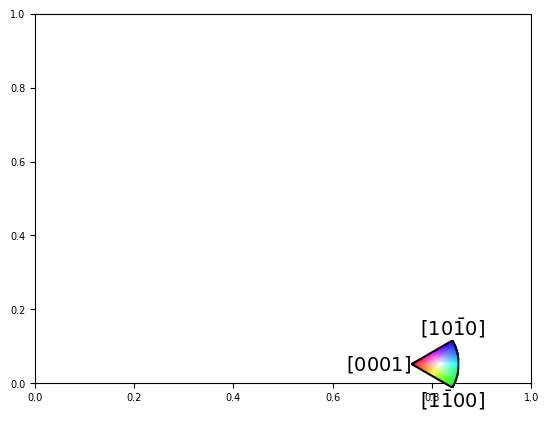

In [ ]:
fig,ax = plt.subplots()
ax_ipf = fig.add_axes([0.7, 0.1, 0.1, 0.1], projection="ipf", symmetry=ori.symmetry, zorder=2)
ax_ipf.plot_ipf_color_key(show_title=False)
plt.rcParams.update(
    {
        "font.size": 8,

    }
)
ax_ipf.patch.set_facecolor("None")
print(ax_ipf.artists)


## Test orientation reading

<div class="alert alert-warning"> Warning everything after here is experimental for now</div>

## Test orientation reading

<div class="alert alert-warning"> Warning everything after here is experimental for now</div>

#### Read phase using orix

In [ ]:
    ori=quaternion.Orientation.from_euler(eangs.transpose(),phase.point_group)
    v = Vector3d([[1, 0, 0], [0, 1, 0], [0, 0, 1]])


    ipfkey_z = plot.IPFColorKeyTSL(phase.point_group)
    ipfkey_x = plot.IPFColorKeyTSL(phase.point_group,v[0])
    ipfkey_y = plot.IPFColorKeyTSL(phase.point_group,v[1])
    # ori.symmetry = ipfkey.symmetry
    rgb_z = ipfkey_z.orientation2color(ori)
    rgb_x = ipfkey_x.orientation2color(ori)
    rgb_y = ipfkey_y.orientation2color(ori)

In [ ]:
# with open f as 
# phase = f['UserInfo']['Phases']["1"][:]

from orix import quaternion
from orix.vector import Miller, Vector3d
from orix import plot

# eangs.transpose()
phase_loc = Path(r"C:\Users\berners\AstroEBSD_v2\phases")
with open(phase_loc.joinpath("phasefiles").joinpath(f"{phaseString[0][0].decode("utf-8")}.pha")) as f:
    s = f.readlines()

i = 0
cif = ""
for line in s:
    if line=="$cif\n":
        cif = s[i+1]
        cif = cif[:-1]
    i+=1
cif

phase = c_map.Phase.from_cif(phase_loc.joinpath("cifs").joinpath(f"{cif}"))

AttributeError: 'str' object has no attribute 'decode'

#### Test whether orientation plotting is  correct
<div class="alert alert-success"> Overlay of IPF from Orix and From MTEX lead to the same results </div>

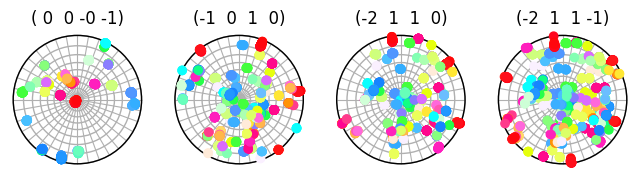

In [ ]:
# ori = quaternion.Orientation.from_euler(eangs[:],phase.point_group)
eangs = [df_plot_all_eval["phi1"].values,df_plot_all_eval["Phi"].values,df_plot_all_eval["phi2"].values]a


# rgb_z
# area = [dfAll["area"]*dfAll["mapResolution"]**2]
eangs =np.array(eangs)#.squeeze()
# size(eangs)
eangs
quaternion
ori=quaternion.Orientation.from_euler(eangs.transpose(),phase.point_group)
v = Vector3d([[1, 0, 0], [0, 1, 0], [0, 0, 1]])


ipfkey_z = plot.IPFColorKeyTSL(phase.point_group)
ipfkey_x = plot.IPFColorKeyTSL(phase.point_group,v[0])
ipfkey_y = plot.IPFColorKeyTSL(phase.point_group,v[1])
# ori.symmetry = ipfkey.symmetry
rgb_z = ipfkey_z.orientation2color(ori)
rgb_x = ipfkey_x.orientation2color(ori)
rgb_y = ipfkey_y.orientation2color(ori)


fig = plt.figure(figsize=(8, 8))

t1 = Miller(hkil=[[0,0,0,1], [1,0,-1,0],[1,1,-2,0],[1,1,-2,1]], phase=phase)
i=0
# figure_kwargs={"layout": "tight", "figsize": (5, 5)}
# for t in t1:
# kwargsAx = { '}
subplots = [141, 142,143,144]
ax = []
for i in range(t1.size):
    t_loc = t1[i]
    ax.append(fig.add_subplot(subplots[i],projection="stereographic"))
    for t in t_loc.symmetrise():
        v = Vector3d(ori.inv().outer(t))
    # v= v.symmetrise()
        kwargs = {}
        ax[i].stereographic_grid(True)
        ax[i].scatter(v,c=rgb_z)
        hkil = (np.round(t.hkil[0]))
        ax[i].set_title(f"({hkil[0]:2.0f} {hkil[1]:2.0f} {hkil[2]:2.0f} {hkil[3]:2.0f})")
t.hkil
    # ax2.scatter()
        # ec=["r", "b"],**figure_kwargs)
    # i+=1


# t1 = Miller(uvw=[[1, 2, 0], [3, 1, 1]], phase=tetragonal)
# t1.scatter(projection = "stereographic", c=["b", "r"], axes_labels=["e1", "e2"])
plt.savefig(exportFolder.joinpath(f'{sample}_PF.pdf'),bbox_inches='tight',dpi=300)
plt.savefig(exportFolder.joinpath(f'{sample}_PF.svg'),bbox_inches='tight')
plt.savefig(exportFolder.joinpath(f'{sample}_PF.png'),bbox_inches='tight')

array([[0.86808623, 1.        , 0.48743067],
       [0.8643724 , 1.        , 0.49046792],
       [0.86581122, 1.        , 0.48023194],
       [0.86553483, 1.        , 0.48631557],
       [0.87248029, 1.        , 0.48335404],
       [1.        , 0.57181391, 0.02945765],
       [1.        , 0.57578655, 0.04078134],
       [1.        , 0.58263099, 0.03904517],
       [1.        , 0.57358266, 0.04466339],
       [1.        , 0.52981675, 0.06305353],
       [1.        , 0.05169217, 0.53052175],
       [1.        , 0.0184191 , 0.56834455],
       [1.        , 0.57168688, 0.02297539],
       [1.        , 0.92185218, 0.85207265],
       [1.        , 0.58178948, 0.02509405],
       [1.        , 0.58206645, 0.03404207],
       [0.5275829 , 1.        , 0.48043361],
       [0.52694818, 0.47902451, 1.        ],
       [0.52695395, 1.        , 0.48021056],
       [1.        , 0.23179371, 0.54945985],
       [0.52534081, 1.        , 0.47978898],
       [0.52913121, 1.        , 0.48079387],
       [0.

In [ ]:
from matplotlib.patches import Polygon
import seaborn as sns

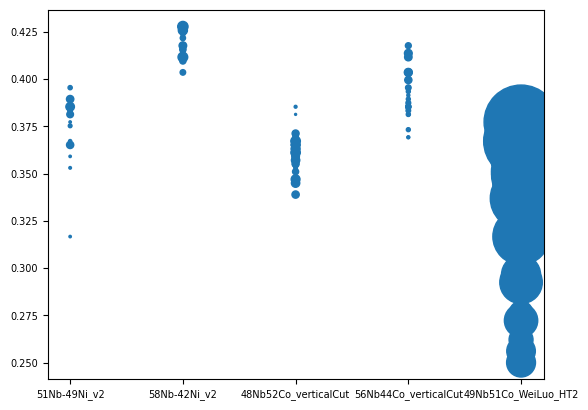

In [ ]:
plt.scatter(df_plot_all_eval['Sample'],df_plot_all_eval.maxIL,s=df_plot_all_eval.Area_micron)


In [ ]:
# plt.scatter(df_plot_all_eval['Sample'],df_plot_all_eval.maxIL,s=df_plot_all_eval.Area_micron)

sns.boxplot(df_plot_all_eval,x='Sample',y='maxIL')
# for df_plot_all_eval_unique sa
df_plot_all_eval.groupby([df_plot_all_eval.index,"Sample"]).apply(lambda x: np.average(x.maxIL, weights=x.Area_micron))

NameError: name 'sns' is not defined

In [ ]:
df_plot_all_eval.groupby([df_plot_all_eval.index,"Sample"]).apply(lambda x: np.average(x.maxIL))#, weights=x.Area_micron))

C:\Users\berners\AppData\Local\Temp\ipykernel_30768\2394498933.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_plot_all_eval.groupby([df_plot_all_eval.index,"Sample"]).apply(lambda x: np.average(x.maxIL))#, weights=x.Area_micron))


   Sample              
0  48Nb52Co_verticalCut    0.362266
   49Nb51Co_WeiLuo_HT2     0.347959
   51Nb-49Ni_v2            0.376515
   56Nb44Co_verticalCut    0.392312
   58Nb-42Ni_v2            0.418609
dtype: float64

### Some more tests
<div class="alert alert-info"> These cells might be useful at a later point to retrieve what we tried to plot </div>

(0.24, 0.46)

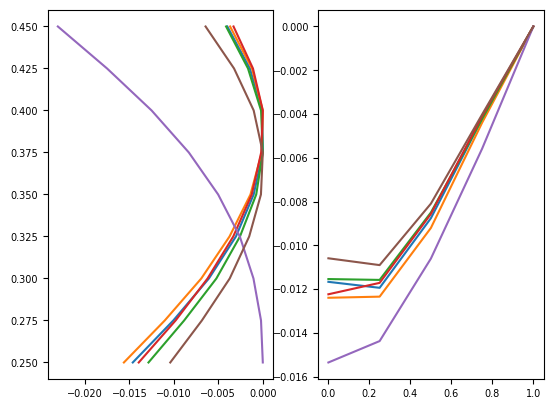

In [ ]:

sample = dfAll['Sample'].unique()[0]
df_plot = dfAll[dfAll['Sample']==sample]
df_plot["NbAndIL"]= df_plot["NbPlot"].astype(str) + '_'+ df_plot["ILPlot"].astype(str)
df_plot["uniquePat"]= df_plot["Area"].astype(str) + '_'+ df_plot["Map"].astype(str)+ '_'+ df_plot["Tile"].astype(str)+ '_'+ df_plot["PatternNum"].astype(str)
fig,ax = plt.subplots(1,2)
# colList = df_plot["Map"].unique()
for uniquePat in df_plot["uniquePat"].unique():
    df_plot_uniquePat = df_plot[df_plot["uniquePat"]==uniquePat]
    maxIL = df_plot_uniquePat[df_plot_uniquePat["DiffValues"]==0]["ILPlot"].values[0]
    maxNb = df_plot_uniquePat[df_plot_uniquePat["DiffValues"]==0]["NbPlot"].values[0]
    ILVals = df_plot_uniquePat[df_plot_uniquePat["NbPlot"]==maxNb]["DiffValues"]
    IL_x = df_plot_uniquePat[df_plot_uniquePat["NbPlot"]==maxNb]["ILPlot"]
    NbVals = df_plot_uniquePat[df_plot_uniquePat["ILPlot"]==maxIL]["DiffValues"]
    Nb_x = df_plot_uniquePat[df_plot_uniquePat["ILPlot"]==maxIL]["NbPlot"]
    ax[0].plot(ILVals,IL_x)
    ax[1].plot(Nb_x,NbVals)
ax[0].set_ylim()

C:\Users\berners\AppData\Local\Temp\ipykernel_2920\2088081974.py:96: OptimizeWarning: Covariance of the parameters could not be estimated
  [params,cov]=curve_fit(f,NbVals_plot,meanValNb)


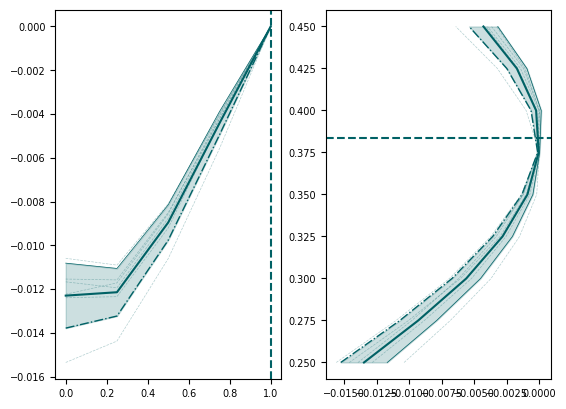

In [ ]:
    def f(x, a, b,c,d,e):
        return a * x**3 + b*x**3 +c*x**2 + d*x +e    


    df_plot = dfAll[dfAll['Sample']==sample]
    df_plot["NbAndIL"]= df_plot["NbPlot"].astype(str) + '_'+ df_plot["ILPlot"].astype(str)
    df_plot["uniquePat"]= df_plot["Area"].astype(str) + '_'+ df_plot["Map"].astype(str)+ '_'+ df_plot["Tile"].astype(str)+ '_'+ df_plot["PatternNum"].astype(str)
    
    fig,ax = plt.subplots(1,2)    
    uniqueMaps = df_plot["Map"].unique()
    plottedColorList = []
    ax_IL = ax[1]
    ax_Nb = ax[0]
    ILValList = {}
    maxILList = {}
    NbValList = {}
    maxNbList = {}  
    IL_xs = { }
    Nb_xs = {}
    for i in range(len(uniqueMaps)):
        ILValList[i]=[]
        maxILList[i]=[]
        NbValList[i]=[]
        maxNbList[i]=[]
        IL_xs[i]=[]
        Nb_xs[i]=[]
    for uniquePat in df_plot["uniquePat"].unique():


        df_plot_uniquePat = df_plot[df_plot["uniquePat"]==uniquePat]

        maxIL = df_plot_uniquePat[df_plot_uniquePat["DiffValues"]==0]["ILPlot"].values[0]
        maxNb = df_plot_uniquePat[df_plot_uniquePat["DiffValues"]==0]["NbPlot"].values[0]
        ILVals = df_plot_uniquePat[df_plot_uniquePat["NbPlot"]==maxNb]["DiffValues"]
        IL_x = df_plot_uniquePat[df_plot_uniquePat["NbPlot"]==maxNb]["ILPlot"]
        NbVals = df_plot_uniquePat[df_plot_uniquePat["ILPlot"]==maxIL]["DiffValues"]
        Nb_x = df_plot_uniquePat[df_plot_uniquePat["ILPlot"]==maxIL]["NbPlot"]

        currentMap = df_plot_uniquePat["Map"].values[0] 
        colNum = np.where(uniqueMaps == currentMap)[0][0]
        color = colorList[colNum] 

        maxILList[colNum].append(IL_x.values[np.where(max(ILVals.values)==ILVals.values)[0][0]])
        maxNbList[colNum].append(Nb_x.values[np.where(max(NbVals.values)==NbVals.values)[0][0]])
        
        IL_xs[colNum]=IL_x.values
        Nb_xs[colNum]=Nb_x.values

        NbValList[colNum].append(NbVals.values)
        ILValList[colNum].append(ILVals.values)        
        # ILValList[colNum].append(ILVals)
        # ILValList[colNum}"]

    for colNum in range(len(uniqueMaps)):

        outlierFilter = np.where(abs(maxILList[colNum]-np.mean(maxILList[colNum])) < np.max([(np.std(maxILList[colNum])*2),0.05]))
        outlierFilterNb = np.where(abs(maxNbList[colNum]-np.mean(maxNbList[colNum])) < np.max([np.std(maxNbList[colNum])*2,0.25]))
        plotValsIL = np.array(ILValList[colNum])[outlierFilter]
        plotValsNb = np.array(NbValList[colNum])[outlierFilterNb]
        ILVals_plot = IL_xs[colNum]
        NbVals_plot = Nb_xs[colNum]

        meanValIL = np.mean(plotValsIL,0) 
        stdValIL = np.std(plotValsIL,0)

        ax_IL.plot(np.mean(plotValsIL,0),ILVals_plot,color=colorList[colNum])
        ax_IL.plot(np.transpose(plotValsIL),ILVals_plot,color=colorList[colNum],alpha=0.3,linestyle='--',linewidth=0.5)
        ax_IL.plot(meanValIL+stdValIL,ILVals_plot,color = colorList[colNum] ,linewidth=0.5)
        ax_IL.plot(meanValIL-stdValIL,ILVals_plot,colorList[colNum],linewidth=1,linestyle = '-.' )
        ax_IL.fill_betweenx(ILVals_plot, meanValIL-stdValIL, meanValIL+stdValIL, color=colorList[colNum], alpha=0.2)


        meanValNb = np.mean(plotValsNb,0)
        stdValNb = np.std(plotValsNb,0)

        
        ax_Nb.plot(NbVals_plot,np.mean(plotValsNb,0),color=colorList[colNum])
        ax_Nb.plot(NbVals_plot,np.transpose(plotValsNb),color=colorList[colNum],alpha=0.3,linestyle='--',linewidth=0.5)
        ax_Nb.plot(NbVals_plot,meanValNb+stdValNb,color = colorList[colNum] ,linewidth=0.5)
        ax_Nb.plot(NbVals_plot,meanValNb-stdValNb,colorList[colNum],linewidth=1,linestyle = '-.' )
        ax_Nb.fill_between(NbVals_plot, meanValNb-stdValNb, meanValNb+stdValNb, color=colorList[colNum], alpha=0.2)
    # from scipy.optimize import curve_fit

    

        [params,cov]=curve_fit(f,ILVals_plot,meanValIL)
        f_xValues=np.linspace(min(ILVals_plot),max(ILVals_plot),100)
        plotValues = f(f_xValues,params[0],params[1],params[2],params[3],params[4])
        # f(f_xValues,params[0],params[1],params[2],params[3],params[4])
        maxIL = f_xValues[plotValues.argmax()]
        # plt.plot(plotValues,f_xValues)
        # plt.plot(meanVal,ILVals_plot)
        ax_IL.axhline(y=maxIL,color=colorList[colNum],linestyle='--')


        [params,cov]=curve_fit(f,NbVals_plot,meanValNb)
        f_xValues=np.linspace(min(NbVals_plot),max(NbVals_plot),100)
        plotValues = f(f_xValues,params[0],params[1],params[2],params[3],params[4])
        # f(f_xValues,params[0],params[1],params[2],params[3],params[4])
        maxIL = f_xValues[plotValues.argmax()]
        # plt.plot(plotValues,f_xValues)
        # plt.plot(meanVal,ILVals_plot)
        ax_Nb.axvline(x=maxIL,color=colorList[colNum],linestyle='--')
        # a